# Challenge 3: evaluación final e inferencia

El modelo ya fue seleccionado. Ahora debes abrir el conjunto de test una sola vez, comunicar su desempeño y comprobar que el pipeline puede reutilizarse con datos nuevos.

**Entradas:** `test.csv`, `data_contract.json` y `champion_model.joblib`  
**Salidas:** `test_metrics.json`, `batch_predictions.csv`

In [1]:
from google.colab import drive
from pathlib import Path
import os

drive.mount("/content/drive")

carpeta = Path("/content/drive/MyDrive/lecture6/challenge")

if not carpeta.is_dir():
    raise FileNotFoundError(f"No se encontró: {carpeta}")

os.chdir(carpeta)

archivos_requeridos = [
    carpeta / "data" / "processed" / "test.csv",
    carpeta / "artifacts" / "data_contract.json",
    carpeta / "artifacts" / "training_metadata.json",
    carpeta / "artifacts" / "champion_model.joblib"
]

for archivo in archivos_requeridos:
    if not archivo.is_file():
        raise FileNotFoundError(f"Falta el archivo: {archivo}")

print("Carpeta de trabajo:", Path.cwd())
print("Archivos requeridos encontrados.")

Mounted at /content/drive
Carpeta de trabajo: /content/drive/MyDrive/lecture6/challenge
Archivos requeridos encontrados.


In [2]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

In [3]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga del modelo y del conjunto de prueba

In [5]:
contract = json.loads(
    (ARTIFACTS_DIR / "data_contract.json")
    .read_text(encoding="utf-8")
)

training_metadata = json.loads(
    (ARTIFACTS_DIR / "training_metadata.json")
    .read_text(encoding="utf-8")
)

model = joblib.load(
    ARTIFACTS_DIR / "champion_model.joblib"
)

champion_name = training_metadata.get("champion_name")

if champion_name is None:
    champion_name = training_metadata.get("champion")

if champion_name is None:
    raise ValueError("Los metadatos no contienen el nombre del campeón.")

test_df = pd.read_csv(
    PROCESSED_DATA_DIR / "test.csv"
)

feature_columns = contract["features"]

X_test = test_df[feature_columns]
y_test = test_df[contract["target"]]

print("Modelo:", champion_name)
print("Test:", X_test.shape)

Modelo: LogisticRegression
Test: (36, 13)


## 2. Evaluación final

Accuracy test: 0.9722
F1 macro test: 0.9710

Reporte de clasificación:
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        12
           1     0.9333    1.0000    0.9655        14
           2     1.0000    0.9000    0.9474        10

    accuracy                         0.9722        36
   macro avg     0.9778    0.9667    0.9710        36
weighted avg     0.9741    0.9722    0.9720        36



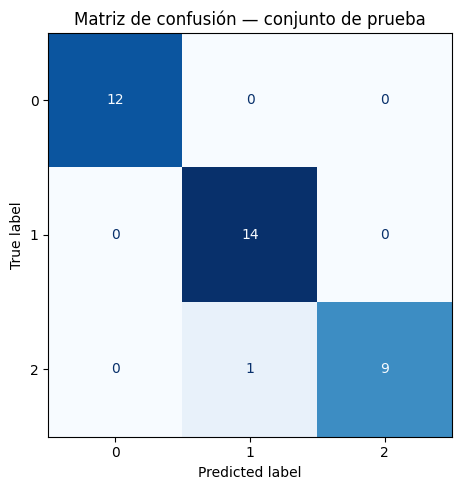


Accuracy CV: 0.9791
Accuracy test: 0.9722
Diferencia test − CV: -0.68 puntos porcentuales

Confusiones observadas:


,clase_real,clase_predicha,cantidad
0,2,1,1


In [6]:
y_pred = model.predict(X_test)

test_accuracy = float(
    accuracy_score(y_test, y_pred)
)

test_f1_macro = float(
    f1_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )
)

print(f"Accuracy test: {test_accuracy:.4f}")
print(f"F1 macro test: {test_f1_macro:.4f}")

print("\nReporte de clasificación:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=model.classes_,
        digits=4,
        zero_division=0
    )
)

fig, ax = plt.subplots(figsize=(6, 5))

confusion_display = ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=model.classes_,
    display_labels=model.classes_,
    cmap="Blues",
    colorbar=False,
    ax=ax
)

ax.set_title("Matriz de confusión — conjunto de prueba")
fig.tight_layout()

fig.savefig(
    REPORTS_DIR / "test_confusion_matrix.png",
    dpi=150
)

plt.show()

# Comparación con la validación cruzada.
cv_accuracy = float(training_metadata["best_cv_score"])

print(f"\nAccuracy CV: {cv_accuracy:.4f}")
print(f"Accuracy test: {test_accuracy:.4f}")
print(
    "Diferencia test − CV:",
    f"{100 * (test_accuracy - cv_accuracy):.2f} puntos porcentuales"
)

# Identificar las confusiones observadas.
confusion_matrix = confusion_display.confusion_matrix

confusion_rows = []

for i, real_class in enumerate(model.classes_):
    for j, predicted_class in enumerate(model.classes_):
        if i != j and confusion_matrix[i, j] > 0:
            confusion_rows.append({
                "clase_real": real_class,
                "clase_predicha": predicted_class,
                "cantidad": int(confusion_matrix[i, j])
            })

if confusion_rows:
    confusions = (
        pd.DataFrame(confusion_rows)
        .sort_values("cantidad", ascending=False)
        .reset_index(drop=True)
    )
    print("\nConfusiones observadas:")
    display(confusions)
else:
    print("\nNo se observaron errores de clasificación en test.")

**Análisis:**

> ¿El desempeño es coherente con validación cruzada? ¿Qué clases se confunden? ¿Hay evidencia de sobreajuste?

**Análisis:**

El desempeño en prueba es coherente con la validación cruzada. La accuracy promedio de CV fue de **97.91 %** y la accuracy de test fue de **97.22 %**, con una diferencia aproximada de **0.68 puntos porcentuales**, calculada con los valores sin redondear. El **F1 macro de test fue 0.9710**, lo que indica un buen desempeño promedio al dar la misma importancia a cada clase.

La matriz de confusión muestra **35 aciertos de 36 ejemplos**. Se clasificaron correctamente los 12 ejemplos de la clase 0, los 14 de la clase 1 y 9 de los 10 de la clase 2. El único error fue un ejemplo de la **clase 2 clasificado como clase 1**. Por ello, el recall de la clase 2 fue de **0.90** y la precisión de la clase 1 fue de **0.9333**.

No se observa una caída importante del desempeño que sugiera sobreajuste fuerte. Aunque la accuracy promedio de entrenamiento fue del **100 %**, los resultados de CV y test son cercanos y se mantienen altos. Sin embargo, esto no descarta completamente el sobreajuste: el conjunto de prueba contiene solo **36 ejemplos**, y cada error cambia la accuracy aproximadamente **2.78 puntos porcentuales**.

El modelo se mantuvo fijo durante la evaluación, sin reajustar hiperparámetros después de observar los resultados de test.

## 3. Función de inferencia

In [7]:
feature_columns = contract["features"]

def predict(records: pd.DataFrame) -> pd.DataFrame:
    """Valida el esquema y devuelve clases y probabilidades."""

    if not isinstance(records, pd.DataFrame):
        raise TypeError("La entrada debe ser un DataFrame.")

    if records.empty:
        raise ValueError("La entrada no puede estar vacía.")

    if records.columns.duplicated().any():
        raise ValueError("La entrada contiene columnas duplicadas.")

    missing_columns = [
        column
        for column in feature_columns
        if column not in records.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Faltan columnas requeridas: {missing_columns}"
        )

    # Seleccionar y ordenar las características.
    ordered_records = records.loc[:, feature_columns].copy()

    # Verificar que las características sean numéricas.
    for column in feature_columns:
        try:
            ordered_records[column] = pd.to_numeric(
                ordered_records[column],
                errors="raise"
            )
        except (ValueError, TypeError) as error:
            raise ValueError(
                f"La columna '{column}' contiene valores no numéricos."
            ) from error

    numeric_values = ordered_records.to_numpy(dtype=float)

    if np.isinf(numeric_values).any():
        raise ValueError("La entrada contiene valores infinitos.")

    # Los nulos pueden ser tratados por el imputador del pipeline.
    predictions = model.predict(ordered_records)
    probabilities = model.predict_proba(ordered_records)

    result = pd.DataFrame(
        {"prediction": predictions},
        index=records.index
    )

    for position, class_label in enumerate(model.classes_):
        result[f"probability_{class_label}"] = (
            probabilities[:, position]
        )

    return result

## 4. Predicción por lotes

In [8]:
# Simulación: estas filas provienen de test.
# No constituyen datos nuevos independientes.
new_records = X_test.iloc[:5].copy()

batch_predictions = predict(new_records)

display(batch_predictions)

batch_predictions.to_csv(
    REPORTS_DIR / "batch_predictions.csv",
    index=False
)

print(
    "Predicciones guardadas:",
    REPORTS_DIR / "batch_predictions.csv"
)

,prediction,probability_0,probability_1,probability_2
0,0,0.999671,0.000307,0.000023
1,1,0.007051,0.540423,0.452526
2,0,0.992000,0.007664,0.000336
3,1,0.289967,0.707467,0.002565
4,1,0.033032,0.962313,0.004655


Predicciones guardadas: /content/drive/MyDrive/lecture6/challenge/reports/batch_predictions.csv


In [9]:
# Comprobar que el orden de entrada no cambia las predicciones.
reversed_records = new_records[feature_columns[::-1]]

pd.testing.assert_frame_equal(
    predict(new_records),
    predict(reversed_records)
)

print("Correcto: la función ordena las características.")

# Comprobar que detecta una columna faltante.
try:
    predict(
        new_records.drop(columns=[feature_columns[0]])
    )
except ValueError as error:
    print("Correcto: se detectó la columna faltante.")
    print(error)
else:
    raise AssertionError(
        "La función no detectó la columna faltante."
    )

Correcto: la función ordena las características.
Correcto: se detectó la columna faltante.
Faltan columnas requeridas: ['alcohol']


## 5. Reporte final

In [10]:
test_metrics = {
    "model": champion_name,
    "accuracy": test_accuracy,
    "f1_macro": test_f1_macro,
    "n_test_samples": int(len(y_test))
}

metrics_path = REPORTS_DIR / "test_metrics.json"

with metrics_path.open("w", encoding="utf-8") as archivo:
    json.dump(
        test_metrics,
        archivo,
        indent=2,
        ensure_ascii=False
    )

print("Métricas guardadas:", metrics_path)
print(json.dumps(test_metrics, indent=2, ensure_ascii=False))

Métricas guardadas: /content/drive/MyDrive/lecture6/challenge/reports/test_metrics.json
{
  "model": "LogisticRegression",
  "accuracy": 0.9722222222222222,
  "f1_macro": 0.9709618874773139,
  "n_test_samples": 36
}


In [11]:
assert (REPORTS_DIR / "test_metrics.json").exists()
assert (REPORTS_DIR / "batch_predictions.csv").exists()
print("Challenge 3 completado.")

Challenge 3 completado.


## Resumen ejecutivo

| Elemento | Resultado |
|---|---|
| Modelo campeón | LogisticRegression con C = 1.0, guardado junto con su preprocesamiento en un pipeline. |
| Accuracy CV | 97.91 %. |
| Accuracy test | 97.22 %: 35 aciertos de 36 ejemplos. |
| F1 macro test | 0.9710. |
| Clases más confundidas | Se observó un único error: un ejemplo de la clase 2 fue clasificado como clase 1. |
| Principal limitación | El conjunto de prueba contiene solo 36 ejemplos, lo que limita la precisión de la evaluación. La inferencia por lotes utiliza cinco filas de test como simulación, no datos nuevos independientes. |

La función de inferencia generó las predicciones **0, 1, 0, 1 y 1**, junto con las probabilidades estimadas para cada clase. En el segundo registro, las probabilidades de las clases 1 y 2 fueron cercanas: **0.5404** y **0.4525**, respectivamente. El modelo seleccionó la clase 1 por tener la mayor probabilidad, aunque mostró menos confianza que en otros registros.

## Checklist

- [x] Evalué únicamente el modelo campeón.
- [x] No reajusté hiperparámetros después de observar test.
- [x] Implementé validación básica del esquema de entrada.
- [x] Generé predicciones por lotes.
- [x] Guardé las métricas finales.